# Heart Disease Classification with Logistic Regression

Objective is to predict whether a patient has heart disease from 13 clinical measurements using the 303-patient Cleveland heart disease dataset.

**Steps:** explore the data → check what the labels mean → train a logistic regression model → evaluate it → predict for a new patient.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Load and explore the data

In [2]:
data = pd.read_csv("data/heart_disease_data.csv")
print("Rows, columns:", data.shape)
print("Missing values:", int(data.isnull().sum().sum()))
data.head()

Rows, columns: (303, 14)
Missing values: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


There are no missing values. The classes are fairly balanced:

target
0    138
1    165
Name: count, dtype: int64


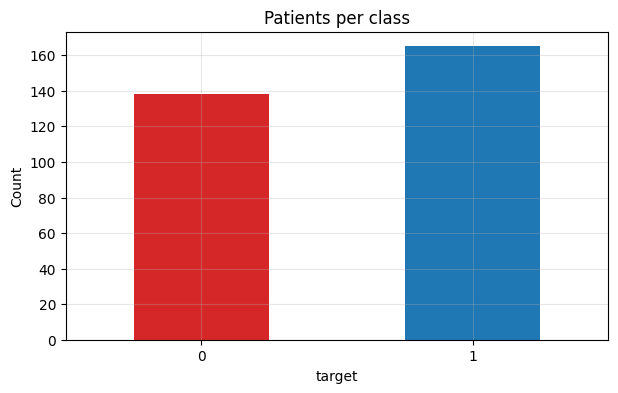

In [3]:
counts = data["target"].value_counts().sort_index()
print(counts)
counts.plot(kind="bar", rot=0, color=["tab:red", "tab:blue"])
plt.title("Patients per class"); plt.xlabel("target"); plt.ylabel("Count")
plt.show()

## 2.Target

In this dataset--> "1 = heart disease and 0 = healthy"

In [4]:
data.groupby("target")[["age", "thalach", "oldpeak", "ca", "exang"]].mean().round(2)

,age,thalach,oldpeak,ca,exang
target,,,,,
0,56.6,139.10,1.59,1.17,0.55
1,52.5,158.47,0.58,0.36,0.14


Every risk marker is **higher for `target = 0`** and maximum heart rate is lower. That pattern says `0` is the group with heart disease and `1` is the group without heart disease.

In [5]:
LABELS = {0: "heart disease", 1: "no heart disease"}

## 3. Which features relate to the target?

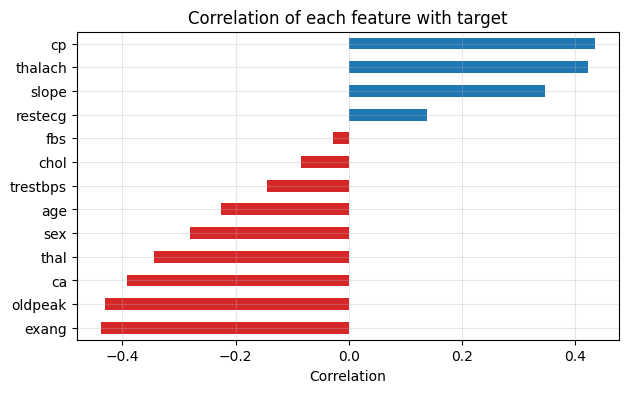

In [6]:
corr = data.corr()["target"].drop("target").sort_values()
corr.plot(kind="barh", color=["tab:red" if v < 0 else "tab:blue" for v in corr])
plt.title("Correlation of each feature with target"); plt.xlabel("Correlation")
plt.show()

Exercise-induced angina, ST depression, vessel count and `thal` are linked to class0 while maximum heart rate and chest pain type are linked to class 1 whichconsistent with the label check above.

## 4. Train/test split

In [7]:
X = data.drop(columns="target")
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=2)
print(X.shape, X_train.shape, X_test.shape)

(303, 13) (242, 13) (61, 13)


## 5. Train the model

In [8]:
model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

## 6. Evaluate

In [9]:
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))
baseline = y.value_counts(normalize=True).max()

print(f"Training accuracy:           {train_acc:.3f}")
print(f"Test accuracy:               {test_acc:.3f}")
print(f"Baseline (always majority):  {baseline:.3f}")

Training accuracy:           0.847
Test accuracy:               0.787
Baseline (always majority):  0.545


5-fold cross-validation uses every patient for testing once:

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)
scores = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression()), X, y, cv=cv)
print("Accuracy per fold:", scores.round(3))
print(f"Mean accuracy: {scores.mean():.3f}  (+/- {scores.std():.3f})")

Accuracy per fold: [0.738 0.852 0.77  0.867 0.867]
Mean accuracy: 0.819  (+/- 0.054)


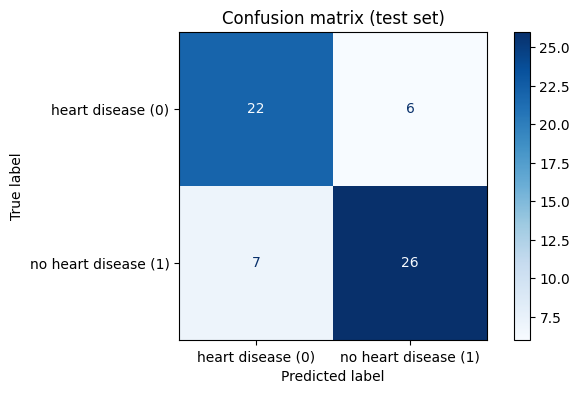

                      precision    recall  f1-score   support

   heart disease (0)       0.76      0.79      0.77        28
no heart disease (1)       0.81      0.79      0.80        33

            accuracy                           0.79        61
           macro avg       0.79      0.79      0.79        61
        weighted avg       0.79      0.79      0.79        61



In [11]:
y_pred = model.predict(X_test)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["heart disease (0)", "no heart disease (1)"]).plot(cmap="Blues")
plt.grid(False); plt.title("Confusion matrix (test set)"); plt.show()

print(classification_report(y_test, y_pred, target_names=["heart disease (0)", "no heart disease (1)"]))

## 7. Predict for a new patient

In [ ]:
def predict_patient(values):
    """values: the 13 features in column order (same as the CSV, without target)."""
    row = pd.DataFrame([values], columns=X.columns)
    cls = int(model.predict(row)[0])
    prob = model.predict_proba(row)[0][cls]
    return f"Predicted: {LABELS[cls]} (confidence {prob:.0%})"


print(predict_patient((62, 0, 0, 140, 268, 0, 0, 160, 0, 3.6, 0, 2, 2)))

Predicted: heart disease (confidence 87%)


## Summary

- Logistic regression separates the two classes well above the baseline.
- Test accuracy on one split is noisy because the test set is small, so the cross-validated figure is the more reliable one.